# Iniciación en Python con Aplicaciones en Aceración (module 05)

**Dr. Edgar Ivan Castro Cedeño**

[edgar.castro@cinvestav.mx](mailto:edgar.castro@cinvestav.mx)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pycalphad import Database, Workspace, as_property
from pycalphad.mapping import BinaryStrategy, plot_binary
from pycalphad import variables as v

from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

In [2]:
def c2k(T):
    return T + 273.15
def k2c(T):    
    return T - 273.15
def x2w(xCC):
    MCC, MFe = 1.2011E+01, 5.5847E+01
    return 100 * xCC*MCC / (xCC*MCC + (1 - xCC)*MFe)
def w2x(wCC):
    MCC, MFe = 1.2011E+01, 5.5847E+01
    return (wCC/MCC) / (wCC/MCC + (100 - wCC)/MFe)

# 1. Contexto metalúrgico

El procesamiento de materiales mediante ciclos térmicos forma parte esencial de la ingeniería metalúrgica.

# 2. Fundamentos Método entálpico

## 2.1 Definiciones básicas

### 2.1.1 Entalpía

La entalpía es una propiedad extensiva que contabiliza el contenido de calor en un sistema termodinámico, dado por la suma de la energía interna y el producto de la presión y el volúmen del sistema.

$$H \equiv U + pV$$

La entalpía se puede transformar en propiedad intensiva al dividirla entre el tamaño del sistema. De esta forma se definen la entalpía molar y la entalpía específica.

$$H_{m} = \frac{H}{n}$$

$$h = \frac{H}{m}$$

En el marco de cálculos térmicos en ingeniería metalúrgica, generalmente se trabaja en términos específicos, i.e., entalpía por unidad de masa.

<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">

- **$H$**: Entalpía, $[\mathrm{J}]$.

- **$H_{m}$**: Entalpía molar, $[\mathrm{J.mol^{-1}}]$.

- **$h$**: Entalpía específica, $[\mathrm{J.kg^{-1}}]$.

- **$m$**: masa, $[\mathrm{kg}]$.

- **$n$**: cantidad de sustancia, $[\mathrm{mol}]$.


- **$U$**: Energía interna, $[\mathrm{J}]$.

- **$p$**: Presión, $[\mathrm{N.m^{-2}}]$.

- **$V$**: Volúmen, $[\mathrm{m^{3}}]$.

</div>

</details>

### 2.1.2 Energía libre de Gibbs

Se elige la energía libre de Gibbs como la función básica para el modelado termodinámico, porque si se conoce, se pueden derivar otras cantidades termodinámicas.

$$G = G\left(T,p,N_i\right)$$

 <center>

| Cantidad | Definición |
|----|----|
| Energía libre de Gibbs | $$G \equiv H - TS$$ |
| Entalpía | $$H = G + TS = G - T\left(\frac{\partial G}{\partial T}\right)_{p,N_i}$$ |
| Entropía | $$S=-\left(\frac{\partial G_m}{\partial T}\right)_{p,N_i}$$ |
| Capacidad calorífica | $$C_p = -T \left(\frac{\partial^2 G}{\partial T^2}\right)_{p,N_i}$$ |
| Potencial químico | $$\mu_i = \left(\frac{\partial G}{\partial N_i}\right)_{T,N_{j\ne i}}$$ |

</center>

## 2.2 Cambio de entalpía en un material

En forma general, el cambio en la entalpía de un material puede ocurrir debido a un cambio de temperatura como a una transición de fase.

### 2.2.1 Material puro

En un material puro las transformaciones de fase ocurren a una temperatura invariante, entonces el cambio de entalpía está dado por:

$$dh = \left( \frac{\partial h}{\partial T}\right)_{p} dT + h_{\mathrm{lat}} d\xi$$

$$dh = C_{p} dT + h_{\mathrm{lat}} d\xi$$

Al graficar entalpía vs temperatura, o capacidad calorífica vs temperatura, la curva presenta discontinuidades a las temperaturas a las que ocurre la transición.

<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">


- **$C_{p}$**: Capacidad calorífica específica, $[\mathrm{J.kg^{-1}.K^{-1}}]$.

- **$h$**: Entalpía específica, $[\mathrm{J.kg^{-1}}]$.

- **$h_{\mathrm{lat}}$**: Calor específico de transformación, $[\mathrm{J.kg^{-1}}]$.

- **$\xi$**: fracción transformada, $[-]$.

</div>

</details>

**Ejemplo:** Hierro puro, usando la base termodinámica para substancias puras de [SGTE](https://www.sgte.net/en/free-pure-elements-database).

In [3]:
# Define pure Fe system for thermodynamic calculation
tdbpath = os.path.join("TDB", "SGTE-unary1991-2010.TDB")
tdb = Database(tdbpath)
comps = ['FE', 'VA']
phases = ['FCC_A1', 'BCC_A2', 'LIQUID']

wks1 = Workspace(
    database = tdb,
    components = comps,
    phases = phases,
    conditions = {
        v.T: (273.15, 1873.15, 1.0),
        v.P: 1e5,
        v.N: 1
    }
)
MWFe = 5.5847E+01 # g/mol

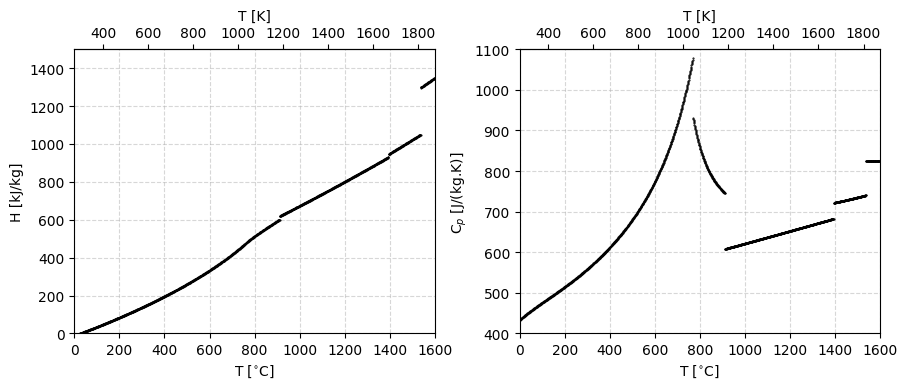

In [4]:
# plot relation between enthalpy - heat capacity and temperature
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(9, 4), sharex=True)

############## plot of h vs T
ax = ax0
x = wks1.get(v.T)
y = wks1.get("HM")/(MWFe)
ax.set_ylabel(f"H [kJ/kg]")
ax.set_ylim(0, 1500)
# plot enthalpy
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')
# annotations


############## plot of apparent Cp vs T
ax = ax1
x = wks1.get(v.T)
heat_capacity = as_property("HM.T")
y = wks1.get(heat_capacity)/(1e-3*MWFe)
ax.set_ylabel(f"C$_p$ [J/(kg.K)]")
ax.set_ylim(400, 1100)
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')

for ax in (ax0, ax1):
    ax.set_xlabel(r"T [$^{\circ}$C]")
    ax.set_xlim(0, 1600)
    ax.grid(ls='--', alpha=0.5)
    secax = ax.secondary_xaxis('top', functions=(c2k, k2c))
    secax.set_xlabel('T [K]')

fig.tight_layout()
plt.show()

In [5]:
# save enthalpy vs temperature and cp vs T curves
x = wks1.get(v.T)
y = wks1.get("HM")/(1e-3*MWFe)
np.savetxt(os.path.join("TDB", "T_vs_h_Fe.txt"), np.column_stack((x, y)), header="T H", comments="")

### 2.2.2 Aleaciones

En las aleaciones las transiciones de fase ocurren sobre un rango de temperaturas, e.g., temperaturas de solidus y de líquidus.

$$dh = \left( \frac{\partial h}{\partial T}\right)_{p} dT + h_{\mathrm{lat}} \left(\frac{d \xi}{dT}\right)_p dT$$

$$dh = \left[ C_{p} + h_{\mathrm{lat}} \left(\frac{d \xi}{dT}\right)_p \right] dT $$

$$dh = C_{p}^{\mathrm{eff}} dT $$

<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">


- **$C_{p}$**: Capacidad calorífica específica, $[\mathrm{J.kg^{-1}.K^{-1}}]$.

- **$C_{p}^{\mathrm{eff}}$**: Capacidad calorífica específica efectiva, $[\mathrm{J.kg^{-1}.K^{-1}}]$.

- **$h$**: Entalpía específica, $[\mathrm{J.kg^{-1}}]$.

- **$h_{\mathrm{lat}}$**: Calor específico de transformación, $[\mathrm{J.kg^{-1}}]$.

- **$\xi$**: fracción transformada, $[-]$.

</div>

</details>

**Ejemplo:** Acero, usando una base termodinámica para substancias aceros distribuida con el software [OpenCalphad](https://www.opencalphad.com/).

In [6]:
# Define an base-Fe alloy system for thermodynamic calculation
tdbpath = os.path.join("TDB", "steel1.TDB")
tdb = Database(tdbpath)
comps = ["C", "FE", "VA"]
phases = [
    "FCC_A1", 
    "BCC_A2", 
    "CEMENTITE",
    #"GRAPHITE", 
    "LIQUID"
]
pctC = 0.4
wks2 = Workspace(
    database = tdb,
    components = comps,
    phases = phases,
    conditions = {
        v.T: (273.15, 1873.15, 1.0),
        v.P: 1e5,
        v.N: 1,
        v.X('C'):  w2x(pctC)
    }
)
MWFe = 5.5847E+01 # g/mol
MWCC = 1.2011E+01 # g/mol
MWMix = w2x(pctC)*MWCC + (1-w2x(pctC)) * MWFe

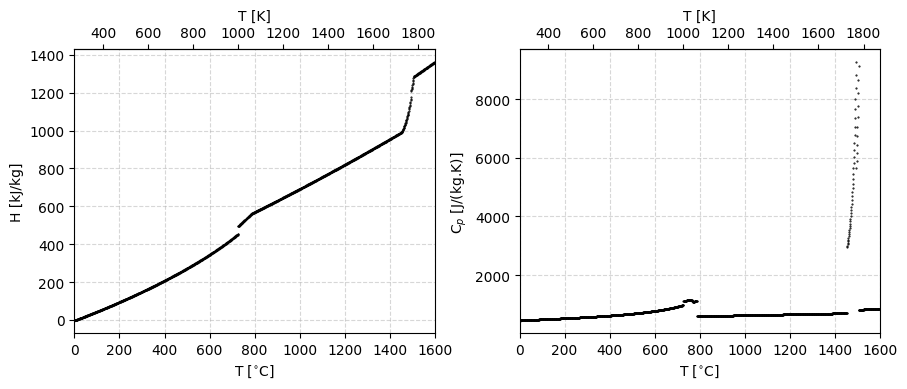

In [7]:
# plot relation between enthalpy - heat capacity and temperature
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(9, 4), sharex=True)

############## plot of h vs T
ax = ax0
x = wks2.get(v.T)
y = wks2.get("HM")/(MWMix)
ax.set_ylabel(f"H [kJ/kg]")
#ax.set_ylim(0, 1500)
# plot enthalpy
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')
# annotations


############## plot of apparent Cp vs T
ax = ax1
x = wks2.get(v.T)
heat_capacity = as_property("HM.T")
y = wks2.get(heat_capacity)/(1e-3*MWMix)
ax.set_ylabel(f"C$_p$ [J/(kg.K)]")
#ax.set_ylim(400, 4500)
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')

for ax in (ax0, ax1):
    ax.set_xlabel(r"T [$^{\circ}$C]")
    ax.set_xlim(0, 1600)
    ax.grid(ls='--', alpha=0.5)
    secax = ax.secondary_xaxis('top', functions=(c2k, k2c))
    secax.set_xlabel('T [K]')

fig.tight_layout()
plt.show()

In [8]:
# save enthalpy vs temperature and cp vs T curves
x = wks2.get(v.T)
y = wks2.get("HM")/(1e-3*MWFe)
np.savetxt(os.path.join("TDB", "T_vs_h_steel.txt"), np.column_stack((x, y)), header="T H", comments="")

## 2.3 Método entálpico vs método Cp

El principio del método entálpico consiste en



**Formulación general:**

$$\rho \frac{\partial h}{\partial t} = - \mathbf{\nabla} \cdot \mathbf{q} + S_{h}$$


### 2.3.1 Formulación entálpica

**Conducción de calor (formulación entálpica)**:

$$\mathbf{q} = - \lambda \mathbf{\nabla} T$$

$$\rho \frac{\partial h}{\partial t} = \mathbf{\nabla} \cdot \left(\lambda \mathbf{\nabla}T \right) + S_{h}$$

$$T = T^{*} + \frac{\partial T}{\partial H} \left(h - h^{*}\right)$$

### 2.3.2 Formulación Cp

**Conducción de calor en sólidos con densidad, capacidad calorífica, y conductividad térmica constantes:**
$$ \rho \frac{\partial \left(C_{p} T\right)}{\partial t} = \lambda \nabla^2 T + S_{h}$$


$$\rho \left[ C_{p} + T \cancel{\left(\frac{d C_{p}}{d T}\right)} \right] \frac{\partial T}{\partial t} = \lambda \nabla^2 T + S_{h}$$

$$\rho C_{p} \frac{\partial T}{\partial t} = \lambda \nabla^2 T + S_{h}$$

# 2.4 Obtención de otros datos termodinámicos

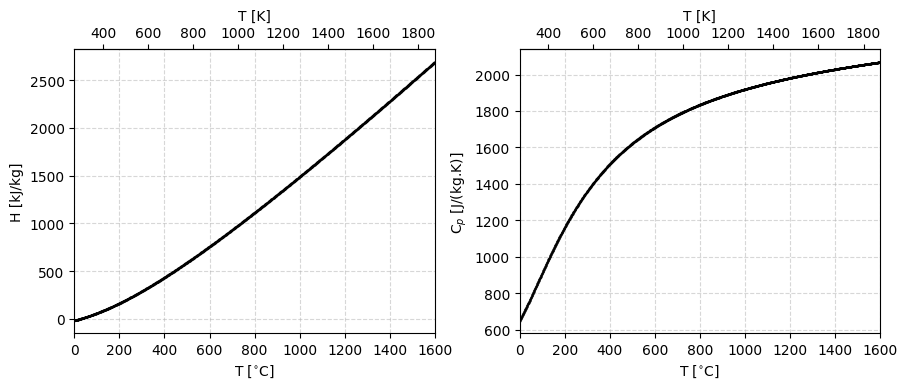

In [13]:
#%% Graphite
tdbpath = os.path.join("TDB", "SGTE-unary1991-2010.TDB")
tdb = Database(tdbpath)
comps = ['C', 'VA']
phases = [
    "GRAPHITE", 
]

wks3 = Workspace(
    database = tdb,
    components = comps,
    phases = phases,
    conditions = {
        v.T: (273.15, 1873.15, 1.0),
        v.P: 1e5,
        v.N: 1,
    }
)
MWCC = 1.2011E+01 # g/mol


# plot relation between enthalpy - heat capacity and temperature
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(9, 4), sharex=True)

############## plot of h vs T
ax = ax0
x = wks3.get(v.T)
y = wks3.get("HM")/(MWCC)
ax.set_ylabel(f"H [kJ/kg]")
# plot enthalpy
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')
# annotations


############## plot of apparent Cp vs T
ax = ax1
x = wks3.get(v.T)
heat_capacity = as_property("HM.T")
y = wks3.get(heat_capacity)/(1e-3*MWCC)
ax.set_ylabel(f"C$_p$ [J/(kg.K)]")
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')

for ax in (ax0, ax1):
    ax.set_xlabel(r"T [$^{\circ}$C]")
    ax.set_xlim(0, 1600)
    ax.grid(ls='--', alpha=0.5)
    secax = ax.secondary_xaxis('top', functions=(c2k, k2c))
    secax.set_xlabel('T [K]')

fig.tight_layout()
plt.show()

# save enthalpy vs temperature and cp vs T curves
x = wks3.get(v.T)
y = wks3.get("HM")/(1e-3*MWCC)
np.savetxt(os.path.join("TDB", "T_vs_h_C.txt"), np.column_stack((x, y)), header="T H", comments="")

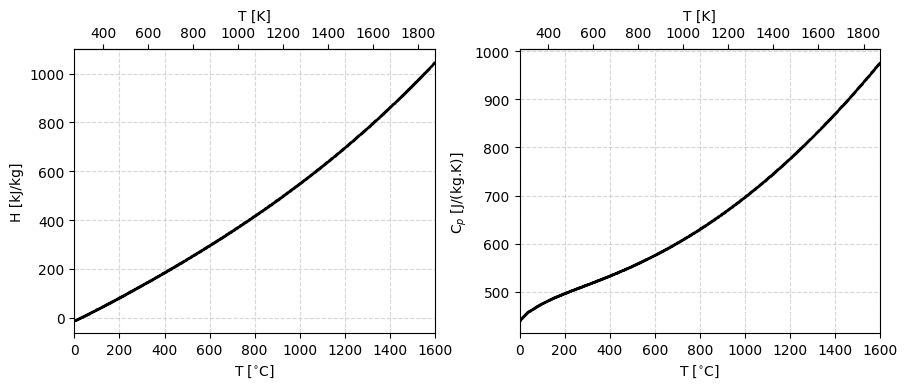

In [14]:
#%% Chrome
tdbpath = os.path.join("TDB", "SGTE-unary1991-2010.TDB")
tdb = Database(tdbpath)
comps = ['CR', 'VA']
phases = [
    "BCC_A2",
    "LIQUID" 
]

wks4 = Workspace(
    database = tdb,
    components = comps,
    phases = phases,
    conditions = {
        v.T: (273.15, 1873.15, 1.0),
        v.P: 1e5,
        v.N: 1,
    }
)
MWCR = 5.1996E+01 # g/mol


# plot relation between enthalpy - heat capacity and temperature
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(9, 4), sharex=True)

############## plot of h vs T
ax = ax0
x = wks4.get(v.T)
y = wks4.get("HM")/(MWCR)
ax.set_ylabel(f"H [kJ/kg]")
# plot enthalpy
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')
# annotations


############## plot of apparent Cp vs T
ax = ax1
x = wks4.get(v.T)
heat_capacity = as_property("HM.T")
y = wks4.get(heat_capacity)/(1e-3*MWCR)
ax.set_ylabel(f"C$_p$ [J/(kg.K)]")
ax.plot(k2c(x), y, ls='', marker='.', markersize=1, color='k')

for ax in (ax0, ax1):
    ax.set_xlabel(r"T [$^{\circ}$C]")
    ax.set_xlim(0, 1600)
    ax.grid(ls='--', alpha=0.5)
    secax = ax.secondary_xaxis('top', functions=(c2k, k2c))
    secax.set_xlabel('T [K]')

fig.tight_layout()
plt.show()

# save enthalpy vs temperature and cp vs T curves
x = wks4.get(v.T)
y = wks4.get("HM")/(1e-3*MWCR)
np.savetxt(os.path.join("TDB", "T_vs_h_Cr.txt"), np.column_stack((x, y)), header="T H", comments="")